# AICS-202 | Laboratory 02
## FGSM Evasion Testing in a Local Sandbox
Course module: 2 | Suggested duration: 4 hours

**Objective:** generate and measure controlled adversarial examples against a classifier you own. Only the local scikit-learn digits data are used.

**Assumption:** white-box access to the locally trained logistic regression model. Results do not generalise automatically to different architectures.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
digits = load_digits()
X = digits.data.astype(float) / 16.0
y = digits.target.astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

def build_model(train_features, train_labels):
    model = LogisticRegression(max_iter=600, random_state=SEED)
    model.fit(train_features, train_labels)
    return model

model = build_model(X_train, y_train)
print('Dataset:', X.shape, '| Train:', len(X_train), '| Test:', len(X_test))
print('Clean test accuracy:', round(accuracy_score(y_test, model.predict(X_test)), 4))

Dataset: (1797, 64) | Train: 1347 | Test: 450
Clean test accuracy: 0.9622


### Part A - Compute the input gradient and FGSM perturbation
Use the gradient of cross-entropy with respect to the normalised image input.

In [2]:
def input_loss_gradient(model, features, labels):
    """Cross-entropy gradient with respect to input, for multinomial logistic regression."""
    probs = model.predict_proba(features)
    targets = np.zeros_like(probs)
    label_indices = np.searchsorted(model.classes_, labels)
    targets[np.arange(len(labels)), label_indices] = 1.0
    return (probs - targets) @ model.coef_

def fgsm(model, features, labels, epsilon=0.10):
    grad = input_loss_gradient(model, features, labels)
    return np.clip(features + epsilon * np.sign(grad), 0.0, 1.0)

Epsilon=0.00 | Accuracy=0.962
Epsilon=0.03 | Accuracy=0.907
Epsilon=0.07 | Accuracy=0.791
Epsilon=0.12 | Accuracy=0.516
Epsilon=0.18 | Accuracy=0.204


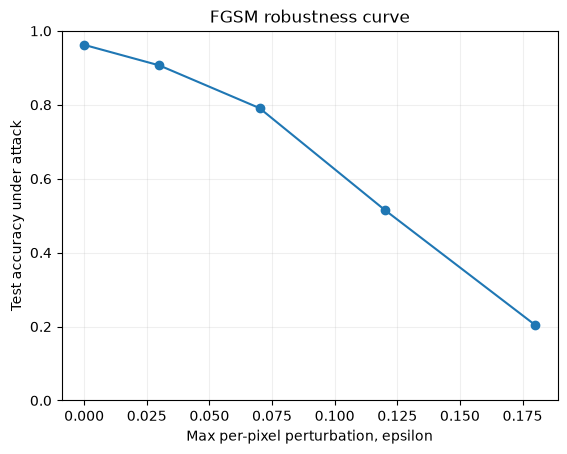

In [3]:
epsilons = [0.00, 0.03, 0.07, 0.12, 0.18]
results = []
for eps in epsilons:
    changed = fgsm(model, X_test, y_test, epsilon=eps)
    acc = accuracy_score(y_test, model.predict(changed))
    results.append((eps, acc))
    print(f'Epsilon={eps:0.2f} | Accuracy={acc:.3f}')
plt.plot([p[0] for p in results], [p[1] for p in results], marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon')
plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve')
plt.ylim(0, 1); plt.grid(alpha=.2); plt.show()

### Part B - Display clean and adversarial samples

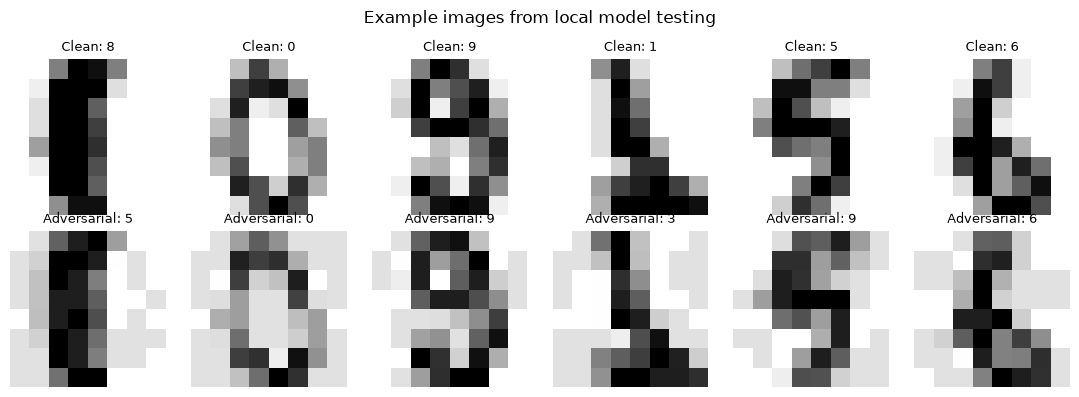

Max observed L-infinity change: 0.12


In [4]:
epsilon = 0.12
adversarial = fgsm(model, X_test, y_test, epsilon=epsilon)
fig, axes = plt.subplots(2, 6, figsize=(11, 4))
for j in range(6):
    axes[0, j].imshow(X_test[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].imshow(adversarial[j].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title('Clean: ' + str(model.predict(X_test[j:j+1])[0]), fontsize=9)
    axes[1, j].set_title('Adversarial: ' + str(model.predict(adversarial[j:j+1])[0]), fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Example images from local model testing');plt.tight_layout();plt.show()
print('Max observed L-infinity change:', np.max(np.abs(adversarial-X_test)))

eps  | attacked acc | max change | preds changed | share of changes < eps
0.00 | 0.9622 | 0.0000 | 0 | 0.000
0.03 | 0.9067 | 0.0300 | 25 | 0.262
0.05 | 0.8556 | 0.0500 | 48 | 0.262
0.07 | 0.7911 | 0.0700 | 77 | 0.290
0.12 | 0.5156 | 0.1200 | 202 | 0.290
0.18 | 0.2044 | 0.1800 | 342 | 0.317


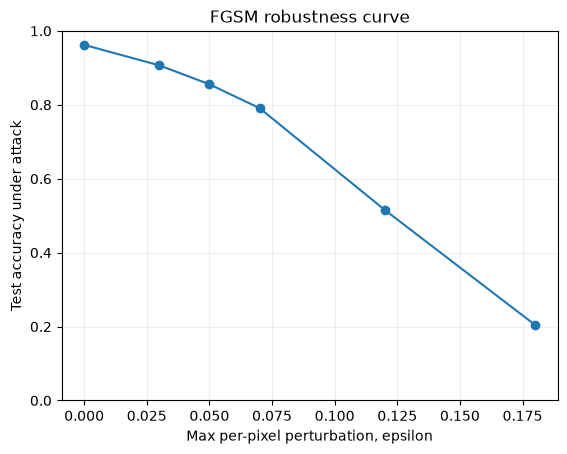

Indices that flip at 0.12: [ 3  4  6  7 10 13 14 18 28 30]


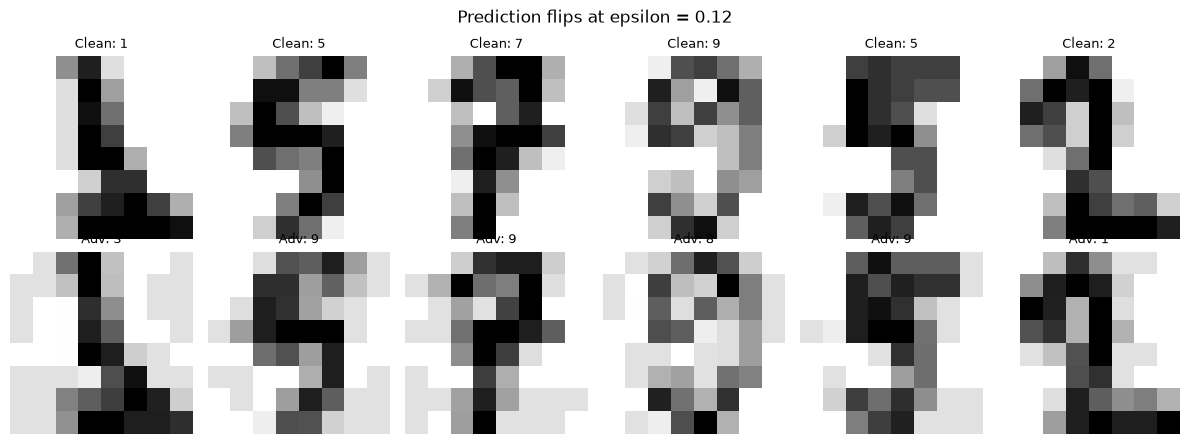

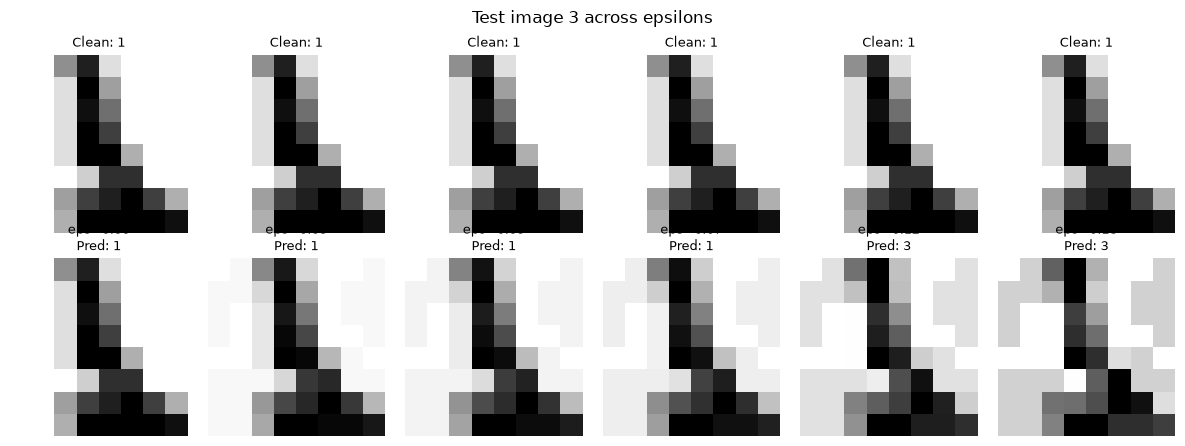

In [5]:
import os, csv
os.makedirs('../results', exist_ok=True)

EXTRA_EPS = 0.05   # <-- CHANGE to your own chosen value (0.01-0.20)
all_eps = sorted(set(epsilons + [EXTRA_EPS]))
clean_pred = model.predict(X_test)

# 1) Results table, with the max change and a clipping check
rows = []
print('eps  | attacked acc | max change | preds changed | share of changes < eps')
for eps in all_eps:
    adv = fgsm(model, X_test, y_test, epsilon=eps)
    pred = model.predict(adv)
    acc = accuracy_score(y_test, pred)
    diff = np.abs(adv - X_test)
    max_change = diff.max()
    flipped = int(np.sum(pred != clean_pred))
    below = float(np.mean(diff < eps - 1e-9)) if eps > 0 else 0.0
    rows.append((eps, round(acc, 4), round(float(max_change), 4), flipped, round(below, 3)))
    print(f'{eps:.2f} | {acc:.4f} | {max_change:.4f} | {flipped} | {below:.3f}')

with open('../results/lab02_results.csv', 'w', newline='') as f:
    w = csv.writer(f)
    w.writerow(['epsilon', 'attacked_accuracy', 'max_linf_change', 'predictions_changed', 'share_changes_below_eps'])
    w.writerows(rows)

# 2) Robustness curve (saved)
plt.figure()
plt.plot([r[0] for r in rows], [r[1] for r in rows], marker='o')
plt.xlabel('Max per-pixel perturbation, epsilon'); plt.ylabel('Test accuracy under attack')
plt.title('FGSM robustness curve'); plt.ylim(0, 1); plt.grid(alpha=.2)
plt.savefig('../results/lab02_robustness_curve.png', dpi=200); plt.show()

# 3) Six examples that really flip at eps=0.12 (clean right -> attacked wrong)
adv12 = fgsm(model, X_test, y_test, epsilon=0.12)
flip12 = np.where((clean_pred == y_test) & (model.predict(adv12) != y_test))[0]
print('Indices that flip at 0.12:', flip12[:10])
show = flip12[:6]
fig, axes = plt.subplots(2, len(show), figsize=(2 * len(show), 4.5))
for j, i in enumerate(show):
    axes[0, j].imshow(X_test[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title(f'Clean: {clean_pred[i]}', fontsize=9)
    axes[1, j].imshow(adv12[i].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].set_title(f'Adv: {model.predict(adv12[i:i+1])[0]}', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle('Prediction flips at epsilon = 0.12'); plt.tight_layout()
plt.savefig('../results/lab02_pairs_eps012.png', dpi=200); plt.show()

# 4) One image across all epsilons (Worksheet 2: image pair per epsilon)
idx = flip12[0]
fig, axes = plt.subplots(2, len(all_eps), figsize=(2 * len(all_eps), 4.5))
for j, eps in enumerate(all_eps):
    img = fgsm(model, X_test[idx:idx+1], y_test[idx:idx+1], epsilon=eps)
    axes[0, j].imshow(X_test[idx].reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[0, j].set_title(f'Clean: {clean_pred[idx]}', fontsize=9)
    axes[1, j].imshow(img.reshape(8, 8), cmap='gray_r', vmin=0, vmax=1)
    axes[1, j].set_title(f'eps={eps:.2f}\nPred: {model.predict(img)[0]}', fontsize=9)
for ax in axes.ravel(): ax.axis('off')
plt.suptitle(f'Test image {idx} across epsilons'); plt.tight_layout()
plt.savefig('../results/lab02_one_image_all_eps.png', dpi=200); plt.show()

### Student exercises
1. Repeat the experiment using an additional epsilon of your choice between 0.01 and 0.20.
2. Report the clean accuracy, attacked accuracy, maximum perturbation, and an example prediction change.
3. Identify the limits of the experiment, including image size, model type and threat assumptions.

**Deliverables:** robustness curve, selected images, result table and a short analysis. Do not use these methods against third-party systems.